In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = Path("../data/raw/meajor_dataset.csv")   

df = pd.read_csv(DATA_DIR)

#### Step 1: Inital EDA

In [15]:
df.head()

,sender,sender_domain,receiver,receiver_domain,date,subject,content_types,body,urls,url_count,url_length_max,url_length_avg,url_subdom_max,url_subdom_avg,attachment_count,has_attachments,attachment_types,language,source,label
0,d66e9e64b006d6bca649f1c945129c42c43836872b2ead...,enron.com,35c5a9fb9fba3b8737ed7cef2a87e427a73db4fca85f6b...,enron.com,2001-06-29 09:37:04-05:00,[ORGANIZATION] failover plan.,text/plain,"Hi [NAME], \n\nTonight we are rolling out a n...",NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0
1,0907d5c64598aa2639154ed4e1556be615669e40052a1f...,enron.com,aa2c35499eae5999bf6080453cc719a891da2bb0c3803d...,enron.com,2001-06-29 08:39:30-05:00,RE: Intranet Site,text/plain,"[NAME] r these new?\tIntranet Site\n\n[NAME],\...",http://eastpower.dev.corp.enron.com/summary/pj...,3.0,60.0,58.0,3.0,3.0,0.0,False,NaN,en,trec5,0.0
2,7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20...,enron.com,a736837579feb601fbf6c0657d3d93689774afa6491bb9...,enron.com;enron.com,2001-06-29 10:35:17-05:00,FW: [ORGANIZATION] Company information,text/plain,"[NAME]/[NAME],\n\nWe are currently trading und...",NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0
3,8531d54a169c4af106b9ea2165d4986b8cc10fc0a6bb9b...,enron.com,765a3ec4a67e40118d22de5729b05d090a1b59cb443bf6...,enron.com;enron.com,2001-06-29 10:40:02-05:00,New Master Physical,text/plain,[NAME] and [NAME] -\n\nAttached is a worksheet...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0
4,7c3201a5ff8c5985218f1e3f11e330dc0242bbd28c6c20...,enron.com,ce418c97ac415706338972e1dbbd99ebb8c617b5c937a3...,enron.com;enron.com;enron.com,2001-06-29 10:48:00-05:00,FW: [ORGANIZATION]/Mirant GISB,text/plain,FYI. Below is a copy of my communication with ...,NaN,0.0,0.0,0.0,0.0,0.0,0.0,False,NaN,en,trec5,0.0


In [16]:
df.sample(5, random_state=42)

,sender,sender_domain,receiver,receiver_domain,date,subject,content_types,body,urls,url_count,url_length_max,url_length_avg,url_subdom_max,url_subdom_avg,attachment_count,has_attachments,attachment_types,language,source,label
93166,781eb0d8ec79f0655e11a45ba63d7cceaad76283491c12...,cajau.com,c8151cb6e18758f810572bfc19bd74b6376f78c4cb4d29...,flax9.uwaterloo.ca,2007-06-06 16:11:02-09:00,Must have pills,text/plain,[ORGANIZATION] is dedicated to providing you w...,http://hugeraise.hk/\nhttp://hugeraise.hk/,2.0,20.0,20.0,0.0,0.0,0.0,False,NaN,en,trec7,1.0
17303,35c9fd53a8f4a6f2a0023d6ec222f8c9050e5dfb525539...,wt.net,484d7e37f87d4bcfbbac726025d65df7cd405efb32f3b5...,yahoogroups.com,2001-10-25 11:19:14-06:00,Re: *EMCA* Mosquitoes,text/plain,All the many neighbors in the energy industry ...,http://us.click.yahoo.com/Gi0tnD/bQ8CAA/ySSFAA...,2.0,56.0,44.5,2.0,1.5,0.0,False,NaN,en,trec5,0.0
40628,25c90517b971ddb8f09623dfc512d125baaa45724a2488...,dfwfinancials.com,dbbeb4550fea80360a092309fa11105daedbf168e8862f...,enron.com,2002-02-19 14:26:11-06:00,Where do we send the [FINANCIAL_INFO]?,text/plain,"Dear Homeowner,\n\nYou have been pre-approved ...",http://www.jhaevb.info\nhttp://nyr.jhaevb.info,2.0,22.0,22.0,1.0,1.0,0.0,False,NaN,en,trec5,1.0
64788,355c34c8329fa5da5b603477d5f25b7480387280b2284f...,samba.org,f2d78073ba3c44ba2e628c37551de8435b1f699fc3ace5...,lists.samba.org,2007-04-08 21:32:26-04:00,Re: svn commit: samba r[REFERENCE_NUMBER] - in...,text/plain,<|EMAIL|> writes:\n\nAuthor: [NAME]\nDate: [DA...,http://websvn.samba.org/cgi-bin/viewcvs.cgi?vi...,1.0,73.0,73.0,1.0,1.0,0.0,False,NaN,en,trec7,0.0
38042,a3c6fa1369692d6efdc2147cb5f426f785dad71a31300c...,comcast.net,ce44efa99ef454f4ea68835b3eb75d4c724f43e9ac9eff...,enron.com,2002-01-31 06:38:19-05:00,72% off for All New Software. entrepreneurial...,text/html,"Through, took house brought paint. Book busy u...",http://www.shutoff.linchidmch.com/?dYfif.JtJhk...,1.0,59.0,59.0,2.0,2.0,0.0,False,NaN,en,trec5,1.0


In [2]:
df.shape

(108685, 20)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 108685 entries, 0 to 108684
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   sender            108191 non-null  str    
 1   sender_domain     108191 non-null  str    
 2   receiver          106314 non-null  str    
 3   receiver_domain   106314 non-null  str    
 4   date              108685 non-null  str    
 5   subject           107230 non-null  str    
 6   content_types     108684 non-null  str    
 7   body              108684 non-null  str    
 8   urls              64052 non-null   str    
 9   url_count         108685 non-null  float64
 10  url_length_max    108685 non-null  float64
 11  url_length_avg    108685 non-null  float64
 12  url_subdom_max    108685 non-null  float64
 13  url_subdom_avg    108685 non-null  float64
 14  attachment_count  108685 non-null  float64
 15  has_attachments   108685 non-null  bool   
 16  attachment_types  1666 non-null

In [8]:
# Generate descriptive statistics for the dataset
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sender,108191,55562,2a0c86a8fa25e09e3702b5442b2a35f7b59011badd551e...,2050,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sender_domain,108191,28464,enron.com,21684,NaN,NaN,NaN,NaN,NaN,NaN,NaN
receiver,106314,17580,247e0a5daf10ac2f4a2ec564931b09941a066488d3fa53...,4484,NaN,NaN,NaN,NaN,NaN,NaN,NaN
receiver_domain,106314,6366,enron.com,30845,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,108685,107474,2002-03-01 04:10:35+00:00,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subject,107230,68486,RE:,895,NaN,NaN,NaN,NaN,NaN,NaN,NaN
content_types,108684,16,text/plain,70992,NaN,NaN,NaN,NaN,NaN,NaN,NaN
body,108684,103518,Start Date: [DATE]; HourAhead hour: [TIME]; N...,667,NaN,NaN,NaN,NaN,NaN,NaN,NaN
urls,64052,38352,https://stat.ethz.ch/mailman/listinfo/r-help\n...,2552,NaN,NaN,NaN,NaN,NaN,NaN,NaN
url_count,108685.0,NaN,NaN,NaN,3.308138,10.507161,0.0,0.0,1.0,2.0,553.0


In [9]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (missing_values / len(df)) * 100
})

missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

,Missing_Count,Missing_Percentage
attachment_types,107019,98.467130
urls,44633,41.066385
receiver_domain,2371,2.181534
receiver,2371,2.181534
subject,1455,1.338731
sender_domain,494,0.454525
sender,494,0.454525
body,1,0.000920
source,1,0.000920
language,1,0.000920


In [11]:
print("Total duplicate rows:", df.duplicated().sum())
df[df.duplicated()].head()

Total duplicate rows: 13


,sender,sender_domain,receiver,receiver_domain,date,subject,content_types,body,urls,url_count,url_length_max,url_length_avg,url_subdom_max,url_subdom_avg,attachment_count,has_attachments,attachment_types,language,source,label
6927,5c4e1beca70cb840b3b92c4e4d8a7faea5c83bced5cfc4...,convene.com,c13aedee55a2627ff6f4e63f8d8260addc02b1b624eff9...,haas.berkeley.edu,2001-09-09 19:08:47-07:00,Account Information for [REFERENCE_NUMBER],text/plain,"Dear [NAME],\n\n[ORGANIZATION] Support has jus...",http://haas.Izio.convene.com.,1.0,29.0,29.000000,2.0,2.000000,0.0,False,NaN,en,trec5,0.0
24947,bee2c11fd3e0e70c2e539ff943da2a9646957d43506a8e...,williams.com,dde1dfbbbf62bb66d86d5d96a17c2503e64ecb6ca6c8a4...,estutenws11.energy.williams.com,2001-11-20 16:37:00-06:00,[ORGANIZATION] -- today's video newscast,text/html,"Energy News Live Daily Wrap-Up\nDear [NAME],\n...",http://www.energynewslive.com/ImageLogServlet/...,12.0,67.0,59.333333,2.0,1.166667,0.0,False,NaN,en,trec5,0.0
25036,5c4e1beca70cb840b3b92c4e4d8a7faea5c83bced5cfc4...,convene.com,c13aedee55a2627ff6f4e63f8d8260addc02b1b624eff9...,haas.berkeley.edu,2001-11-20 22:07:48-08:00,[ORGANIZATION] - [FILE_NAME] Now Available,text/plain,The Assignment '[FILE_NAME]' for Class: '[ORGA...,http://haas.Izio.convene.com.\nhttp://haas.Izi...,2.0,29.0,29.000000,2.0,2.000000,0.0,False,NaN,en,trec5,0.0
30262,122b74ed9286b66d2181c06e695e658e01e4e41b34e5b9...,concureworkplace.com,14825bba309c0a3ddc0c8ca1a83858b403514306f428b5...,enron.com,2001-12-18 22:21:30-08:00,<<[ORGANIZATION] Document>> - [REFERENCE_NUMBER],text/plain,The Payment status has changed on the followin...,http://expensexms.enron.com,1.0,27.0,27.000000,1.0,1.000000,0.0,False,NaN,en,trec5,0.0
31020,122b74ed9286b66d2181c06e695e658e01e4e41b34e5b9...,concureworkplace.com,ddaf102a810c0dde68e6b8732f1b30927cec037f399640...,enron.com,2001-12-21 22:30:03-08:00,<<[ORGANIZATION] Document>> - [REFERENCE_NUMBER],text/plain,The Payment status has changed on the followin...,http://expensexms.enron.com,1.0,27.0,27.000000,1.0,1.000000,0.0,False,NaN,en,trec5,0.0


In [14]:
# # Inspect the target distribution
df["label"].value_counts(dropna=False)

label
0.0    60650
1.0    48034
NaN        1
Name: count, dtype: int64

In [13]:
# # Inspect the target distribution with percentage
df["label"].value_counts(
    normalize=True,
    dropna=False
).mul(100).round(2)

label
0.0    55.8
1.0    44.2
NaN     0.0
Name: proportion, dtype: float64

In [18]:
categorical_cols = df.select_dtypes(
    include=["object", "str"]
).columns

for col in categorical_cols:
    print(f"\nColumn: {col}", df[col].value_counts().sum())
    print(df[col].value_counts(dropna=False).head(10))


Column: sender 108191
sender
2a0c86a8fa25e09e3702b5442b2a35f7b59011badd551e2933f54a159adb4cd1    2050
67223241bc12e6f54ae6df73ddc1183766c611c325055fdd0f9cefc9795f2f38    1098
cdbd10bb2b0e956fd974e13760e5caa2b9409aa2072e6728d8bd44aa306776b0     669
59a753ea8f7d82a4770a8cb3f719f1cd30fbb14ed93de6e4bc2ef9b48893df33     504
ef1ce51898ba0c7fbb61e46b04be1b5939e3069b5ac5bcb9aefda957a0768315     496
NaN                                                                  494
1044a26c05a5652dedd1274075eaf8988a090c4503d7ebb14eb6e60f9b3a4a30     396
ab0f01296d0ed6cc4bb915e9799af88bf93c91c86934fb40b53bc49a7b7cad7b     359
372000a37c444b2b8d5913b14c62d4e86cd2126f5e282ab70df6cfb2a7dff199     333
bf0ab75751ceed579337d5d0b3fa51a80431abb342f818e6bb1d633ddb20b146     328
Name: count, dtype: int64

Column: sender_domain 108191
sender_domain
enron.com                    21684
gmail.com                     2909
samba.org                     2604
yahoo.com                     2169
hotmail.com                   

In [19]:
categorical_cols = [
    "source",
    "language",
    "content_types",
    "has_attachments"
]

for col in categorical_cols:
    print(f"\n{'=' * 50}")
    print(f"Column: {col}")
    print(f"{'=' * 50}")

    print("\nValue counts:")
    print(
        df[col]
        .value_counts(dropna=False)
        .head(15)
    )

    print("\nPercentage distribution:")
    print(
        df[col]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(2)
        .head(15)
    )


Column: source

Value counts:
source
trec5    49583
trec7    44096
trec6    15005
NaN          1
Name: count, dtype: int64

Percentage distribution:
source
trec5    45.62
trec7    40.57
trec6    13.81
NaN       0.00
Name: proportion, dtype: float64

Column: language

Value counts:
language
en          82175
en;en       21250
ru            827
ja            602
de            383
es            332
zh            315
fr            303
tr;en         284
en;en;en      218
pl            114
de;en         101
uk             91
pt             85
de;de          77
Name: count, dtype: int64

Percentage distribution:
language
en          75.61
en;en       19.55
ru           0.76
ja           0.55
de           0.35
es           0.31
zh           0.29
fr           0.28
tr;en        0.26
en;en;en     0.20
pl           0.10
de;en        0.09
uk           0.08
pt           0.08
de;de        0.07
Name: proportion, dtype: float64

Column: content_types

Value counts:
content_types
text/plain            

In [20]:
# Investigate the suspicious timestamps
df["date_parsed"] = pd.to_datetime(
    df["date"],
    errors="coerce",
    utc=True
)

print("Invalid dates:", df["date_parsed"].isna().sum())

print("\nEarliest timestamp:")
print(df["date_parsed"].min())

print("\nLatest timestamp:")
print(df["date_parsed"].max())

Invalid dates: 0

Earliest timestamp:
1889-05-19 08:59:51+00:00

Latest timestamp:
2102-03-16 15:16:56+00:00


In [21]:
df.nlargest(
    10,
    "date_parsed"
)[["date", "subject", "source", "label"]]

,date,subject,source,label
102016,2102-03-16 23:16:56+08:00,balinese bustard demure,trec7,1.0
102015,2102-03-16 23:16:48+08:00,bowl avertive dick,trec7,1.0
91968,2099-05-27 19:49:15+01:00,When you reach the growth size that you want t...,trec7,1.0
74622,2090-04-25 17:06:21+08:00,her do cutlass,trec7,1.0
74623,2090-04-25 17:06:21+08:00,Or cathy my expiate,trec7,1.0
72044,2090-04-19 23:53:43+08:00,Your penis problem solution.,trec7,1.0
66187,2090-01-23 08:51:04+08:00,At whom marjoram,trec7,1.0
67834,2087-04-11 21:34:42+08:00,"we have A-Z medicines, the only best online p...",trec7,1.0
67831,2087-04-11 21:34:34+08:00,"we have A-Z medicines, the only best online p...",trec7,1.0
73385,2080-04-23 16:58:54-01:00,Increase your length and find out how is she i...,trec7,1.0


#### Step 2: Numerical Feature Analysis

In [22]:
# Select the numerical features
numerical_cols = [
    "url_count",
    "url_length_max",
    "url_length_avg",
    "url_subdom_max",
    "url_subdom_avg",
    "attachment_count"
]

df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
url_count,108685.0,3.308138,10.507161,0.0,0.0,1.000000,2.0,553.0
url_length_max,108685.0,31.371091,205.156377,0.0,0.0,26.000000,48.0,66647.0
url_length_avg,108685.0,26.691328,203.959800,0.0,0.0,24.500000,43.5,66647.0
url_subdom_max,108685.0,0.659539,0.791752,0.0,0.0,1.000000,1.0,5.0
url_subdom_avg,108685.0,0.585495,0.712159,0.0,0.0,0.208333,1.0,5.0
attachment_count,108685.0,0.020785,0.274444,0.0,0.0,0.000000,0.0,61.0


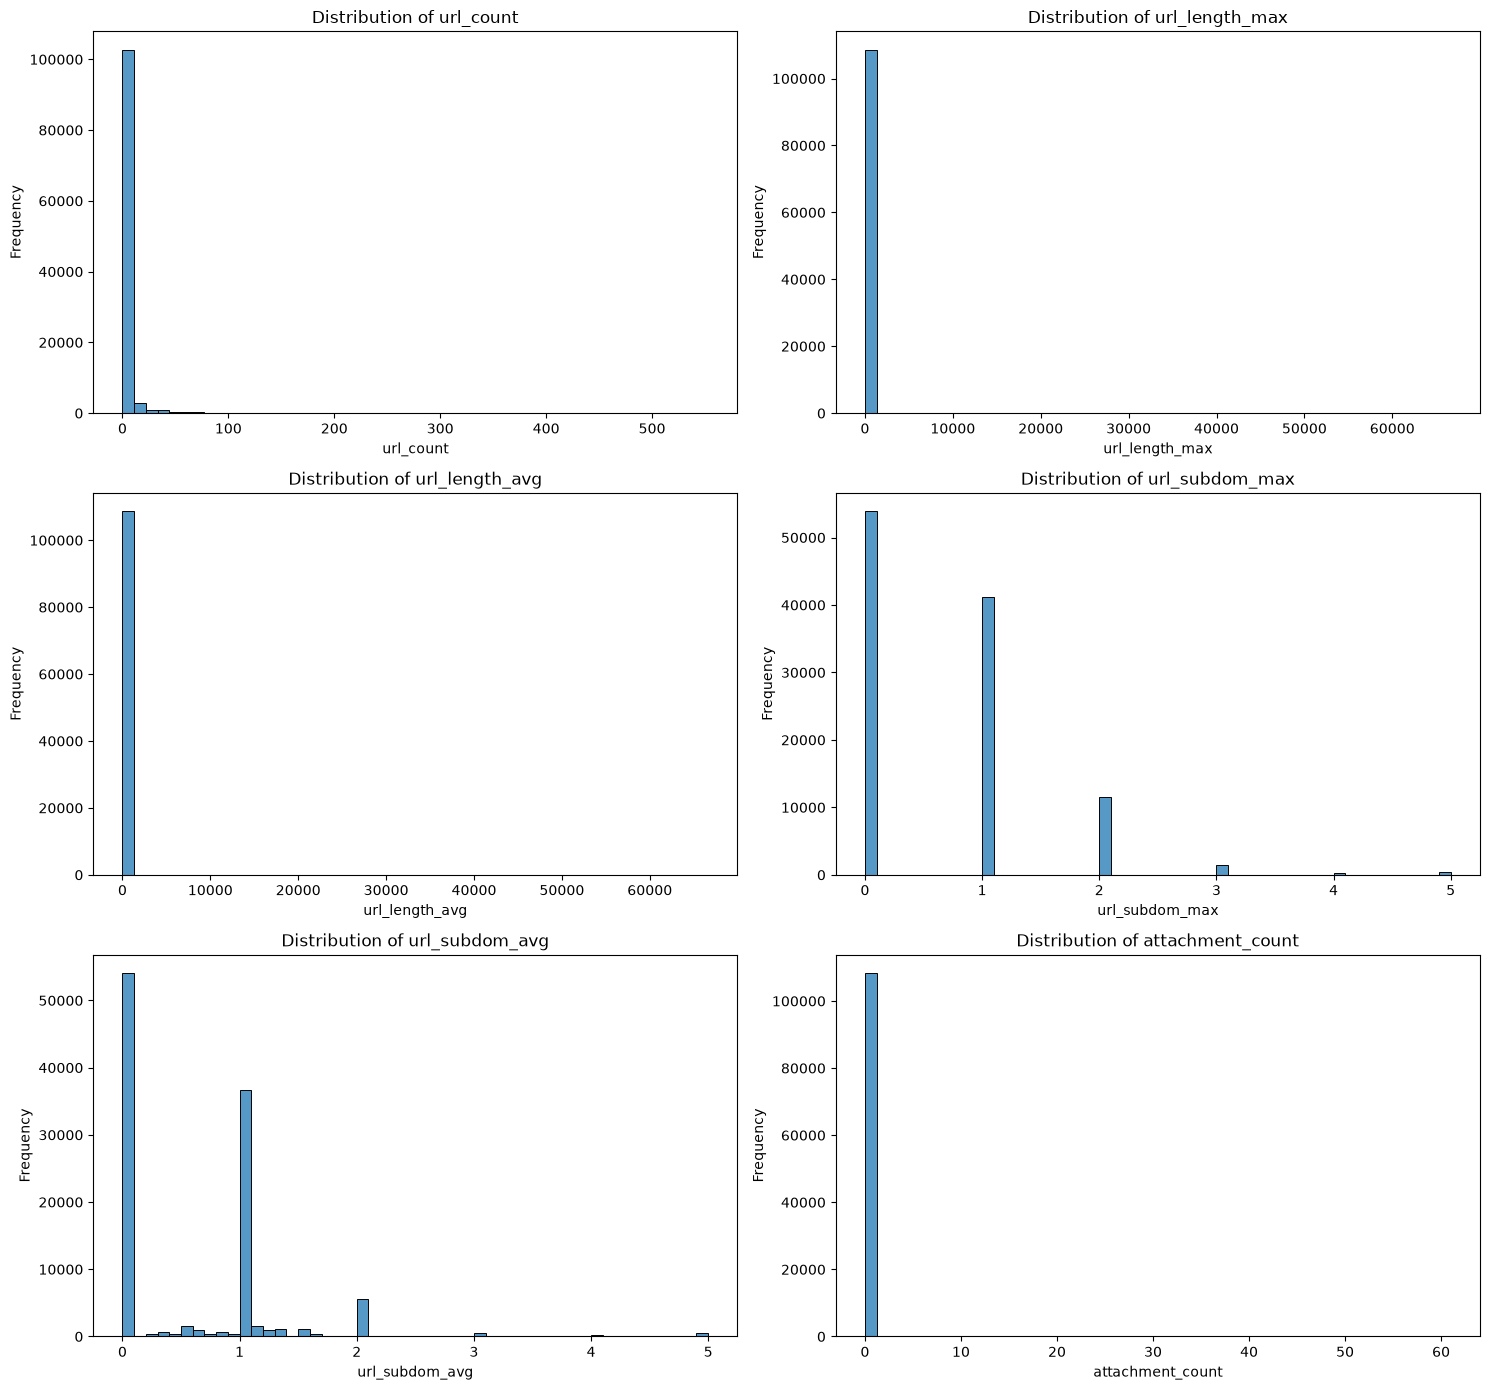

In [23]:
# Plot the distributions using histograms
fig, axes = plt.subplots(3, 2, figsize=(15, 14))

for col, ax in zip(numerical_cols, axes.flatten()):
    sns.histplot(data=df, x=col, bins=50, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

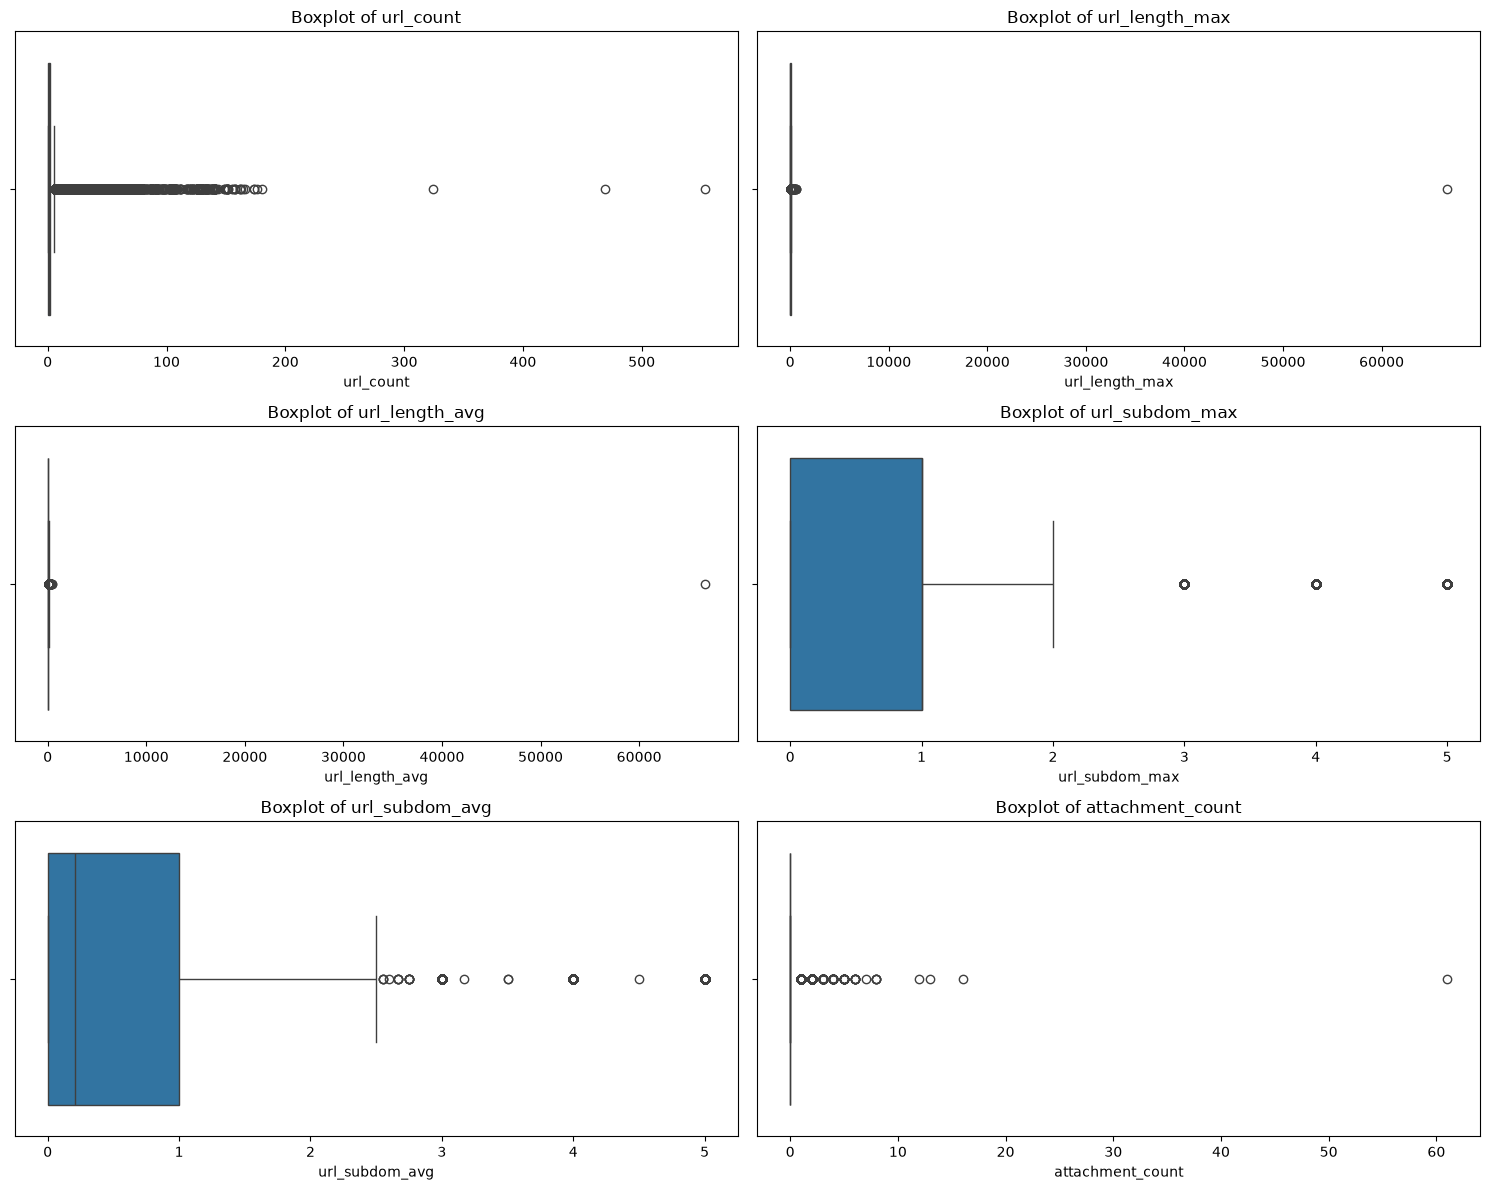

In [24]:
# Investigate the outliers using boxplots
fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for col, ax in zip(numerical_cols, axes.flatten()):
    sns.boxplot(data=df, x=col, ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [25]:
skewness = df[numerical_cols].skew()

skewness.sort_values(ascending=False)

url_length_avg      320.651405
url_length_max      315.012878
attachment_count    109.650376
url_count             9.365420
url_subdom_avg        1.737604
url_subdom_max        1.468099
dtype: float64

In [26]:
# Investigate the extreme URL lengths
cols_to_inspect = [
    "date",
    "subject",
    "urls",
    "url_count",
    "url_length_max",
    "url_length_avg",
    "label"
]

df.nlargest(
    10,
    "url_length_max"
)[cols_to_inspect]

,date,subject,urls,url_count,url_length_max,url_length_avg,label
74569,2007-04-25 16:58:31+09:00,[ORGANIZATION] Blog prediction: [ORGANIZATION]...,http://www.zief.pl/iraq.jpgR0lGODdhaAFHAfYAAIE...,1.0,66647.0,66647.000000,1.0
24342,2001-11-19 19:22:31+00:00,[ORGANIZATION] Bill Pay - New E-Bill,http://alerts.yahoo.com\nhttp://finance.yahoo....,17.0,629.0,77.705882,0.0
24343,2001-11-19 19:23:37+00:00,[ORGANIZATION] Bill Pay - E-Bill Payment Reminder,http://alerts.yahoo.com\nhttp://finance.yahoo....,16.0,629.0,78.562500,0.0
68785,2007-04-14 17:23:38-04:00,Monster Agent Results - [DATE],http://us.js2.yimg.com/us.js.yimg.com/lib/pim/...,24.0,612.0,135.708333,1.0
89308,2007-05-22 03:51:52+02:00,Question from [USERNAME],http://pics.ebaystatic.com/aw/pics/logos/ebay_...,47.0,471.0,60.063830,1.0
59807,2002-05-08 16:49:26-06:00,A special funny website,http://www.google.com\nhttp://www.yahoo.com/\n...,86.0,443.0,90.069767,1.0
42332,2002-03-07 17:07:50-01:00,<|EMOJI|>̷s<|EMOJI|>̬<|EMOJI|>T<|EMOJI|>,http://%67%6F%6F%64%39%39%39%2E%6E%65%74?%4E%6...,1.0,426.0,426.000000,1.0
49510,2002-06-25 02:47:29-05:00,[ORGANIZATION] Checking Card Alert!,http://southtrust-bankonline.com:443/index.php...,1.0,400.0,400.000000,1.0
10659,2001-10-04 09:30:15-05:00,Top 50,http://www.fortune.com/index.jhtml?%2Ffortune%...,1.0,372.0,372.000000,0.0
10784,2001-10-04 17:15:07-05:00,EMCA* For All of You Trying to Work on Set-Bac...,http://rd.yahoo.com/M=168643.1620686.3168692.1...,6.0,366.0,171.666667,0.0


In [27]:
url_text_length = df["urls"].str.len()

url_text_length.describe()

count    64052.000000
mean       311.654749
std        906.933857
min          8.000000
25%         44.000000
50%         87.000000
75%        182.000000
max      66647.000000
Name: urls, dtype: float64

In [28]:
df.loc[
    url_text_length.nlargest(10).index,
    ["urls", "url_count", "url_length_max", "url_length_avg"]
]

,urls,url_count,url_length_max,url_length_avg
74569,http://www.zief.pl/iraq.jpgR0lGODdhaAFHAfYAAIE...,1.0,66647.0,66647.000000
49141,http://www.accuweather.com/adcbin/local_index....,553.0,114.0,56.010850
26800,http://explorer.msn.com/intl.asp\nhttp://a676....,324.0,100.0,83.660494
37067,"http://www.lerdv.com""\nhttp://www.lerdv.com/pa...",469.0,123.0,56.095949
17527,http://www.s2u2.com/passthru.asp?redirectURL=h...,122.0,265.0,170.311475
64220,https://monty.skidmore.edu:443/cgi-bin/index.c...,62.0,256.0,236.048387
63801,https://monty.skidmore.edu:443/cgi-bin/index.c...,62.0,250.0,233.774194
64205,https://monty.skidmore.edu:443/cgi-bin/index.c...,59.0,256.0,236.033898
63715,https://monty.skidmore.edu:443/cgi-bin/index.c...,59.0,250.0,233.593220
64173,https://monty.skidmore.edu:443/cgi-bin/index.c...,56.0,256.0,236.017857


In [29]:
# Examine timestamp ranges by source
df.groupby("source")["date_parsed"].agg(
    ["min", "max", "count"]
)

,min,max,count
source,,,
trec5,1898-06-16 08:01:06+00:00,2034-11-21 06:42:28+00:00,49583
trec6,1889-05-19 08:59:51+00:00,2019-10-29 21:53:50+00:00,15005
trec7,1900-06-27 19:57:30+00:00,2102-03-16 15:16:56+00:00,44096


In [30]:
df.nsmallest(
    10,
    "date_parsed"
)[
    ["date", "subject", "source", "label"]
]

,date,subject,source,label
49714,1889-05-19 16:59:51+08:00,CoQ<|SIMBOL|>ü<|SIMBOL|>v<|SIMBOL|><|SIMBOL|>?...,trec6,1.0
49759,1889-08-19 01:15:51+08:00,[NAME]~ <|SIMBOL|>Ê<|SIMBOL|>ì<|SIMBOL|>k<|SIM...,trec6,1.0
49979,1890-07-19 08:27:09+08:00,[NAME]~ [<|SIMBOL|>Û<|SIMBOL|>ç]<|SIMBOL|>@<|S...,trec6,1.0
50482,1893-08-25 20:16:04+08:00,{<|SIMBOL|>@<|SIMBOL|>è}<|SIMBOL|>b<|SIMBOL|>c...,trec6,1.0
50179,1893-08-29 20:46:26+08:00,<|SIMBOL|>^<|SIMBOL|>^<|SIMBOL|>^<|SIMBOL|>^<|...,trec6,1.0
51200,1893-11-14 17:37:53+08:00,<|SIMBOL|>Ð<|SIMBOL|>z<|SIMBOL|>p<|SIMBOL|>ó<|...,trec6,1.0
51394,1893-11-19 20:11:51+08:00,<|SIMBOL|>÷<|SIMBOL|>|Ãø<|SIMBOL|>o<|SIMBOL|>j...,trec6,1.0
52499,1894-04-28 05:16:16+08:00,<|SIMBOL|>ü<|SIMBOL|>é<|SIMBOL|>L<|SIMBOL|>X<|...,trec6,1.0
52751,1894-06-03 03:31:19+08:00,<|SIMBOL|>b<|SIMBOL|>c<|SIMBOL|>d<|SIMBOL|>e V...,trec6,1.0
52930,1894-06-09 17:30:41+08:00,7<|SIMBOL|>ë<|SIMBOL|>s<|SIMBOL|>W <|SIMBOL|>...,trec6,1.0


#### Step 3: Text EDA

In [31]:
# Check missing and empty text
text_cols = ["subject", "body"]

for col in text_cols:
    missing = df[col].isna().sum()

    empty = (
        df[col]
        .fillna("")
        .str.strip()
        .eq("")
        .sum()
    )

    print(f"\nColumn: {col}")
    print(f"Missing values: {missing}")
    print(f"Empty or whitespace-only values: {empty}")


Column: subject
Missing values: 1455
Empty or whitespace-only values: 1455

Column: body
Missing values: 1
Empty or whitespace-only values: 1


In [32]:
# Analyze subject and body lengths
df["subject_length"] = (
    df["subject"]
    .fillna("")
    .str.len()
)

df["body_length"] = (
    df["body"]
    .fillna("")
    .str.len()
)

df[["subject_length", "body_length"]].describe().T

,count,mean,std,min,25%,50%,75%,max
subject_length,108685.0,42.040870,47.495656,0.0,20.0,32.0,47.0,3701.0
body_length,108685.0,1168.102857,1141.702402,0.0,380.0,797.0,1533.0,30574.0


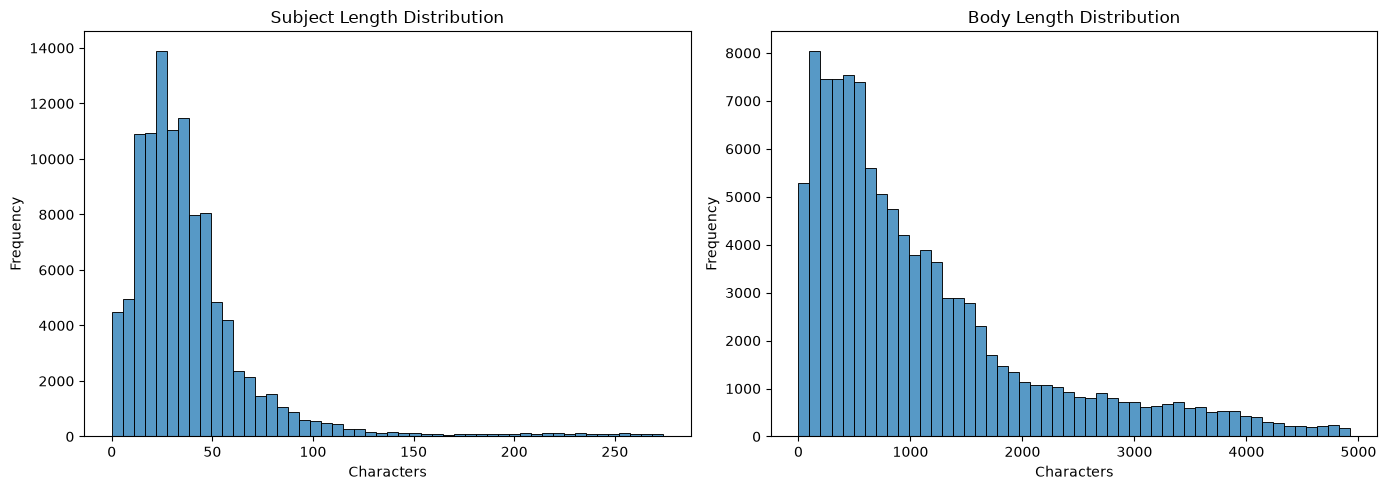

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

subject_limit = df["subject_length"].quantile(0.99)
body_limit = df["body_length"].quantile(0.99)

sns.histplot(
    df.loc[df["subject_length"] <= subject_limit, "subject_length"],
    bins=50,
    ax=axes[0]
)

axes[0].set_title("Subject Length Distribution")
axes[0].set_xlabel("Characters")
axes[0].set_ylabel("Frequency")

sns.histplot(
    df.loc[df["body_length"] <= body_limit, "body_length"],
    bins=50,
    ax=axes[1]
)

axes[1].set_title("Body Length Distribution")
axes[1].set_xlabel("Characters")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [34]:
# Investigate repeated subjects and message bodies
for col in ["subject", "body"]:
    print(f"\nColumn: {col}")

    print(
        "Distinct non-missing values:",
        df[col].nunique()
    )

    print(
        "Values appearing more than once:",
        (df[col].value_counts() > 1).sum()
    )

    print("\nMost frequent values:")

    print(
        df[col]
        .value_counts()
        .head(10)
    )


Column: subject
Distinct non-missing values: 68486
Values appearing more than once: 9947

Most frequent values:
subject
RE:                                                        895
Start Date: [DATE]; HourAhead hour: [TIME];                869
Re:                                                        631
[ORGANIZATION]                                             426
RE: [ORGANIZATION]                                         380
Schedule Crawler: HourAhead Failure                        343
Stock Quote Notification for [ORGANIZATION]                276
Stock Notification for [ORGANIZATION]                      275
Start Date: [DATE]; HourAhead hour: [TIME];  <CODESITE>    224
[NAME]                                                     222
Name: count, dtype: int64

Column: body
Distinct non-missing values: 103518
Values appearing more than once: 1103

Most frequent values:
body
Start Date: [DATE]; HourAhead hour: [TIME];  No ancillary schedules awarded.  No variances detected. \n\n  

In [36]:
# Compare text lengths across target classes
df.groupby("label")[
    ["subject_length", "body_length"]
].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

subject_length                                        body_length  \
               count       mean median        std min   max       count   
label                                                                     
0.0            60650  35.955515   31.0  29.970147   0  3701       60650   
1.0            48034  49.722655   32.0  62.162733   0   669       48034   

                                                   
              mean median          std min    max  
label                                              
0.0    1147.741632  811.0  1080.328137   0  30574  
1.0    1193.830870  783.0  1214.302612   1  28311

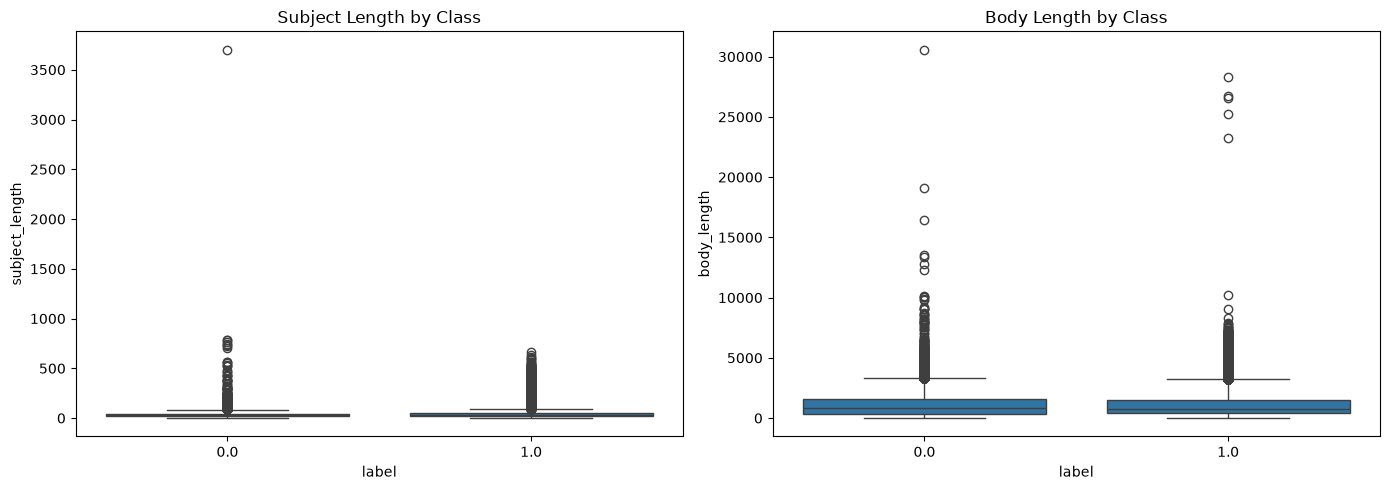

In [35]:
# Visualize the comparison of text lengths across target classes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x="label",
    y="subject_length",
    ax=axes[0]
)

axes[0].set_title("Subject Length by Class")

sns.boxplot(
    data=df,
    x="label",
    y="body_length",
    ax=axes[1]
)

axes[1].set_title("Body Length by Class")

plt.tight_layout()
plt.show()  

### Step 4: Word and Token Analysis

In [37]:
import re
from collections import Counter

def tokenize_text(text):
    if pd.isna(text):
        return []

    text = str(text).lower()

    tokens = re.findall(r"\b[a-z]+\b", text)

    return tokens

In [38]:
sample = "URGENT! Verify your account immediately."

tokenize_text(sample)

['urgent', 'verify', 'your', 'account', 'immediately']

In [39]:
subject_tokens = []

for subject in df["subject"].dropna():
    subject_tokens.extend(tokenize_text(subject))

subject_word_counts = Counter(subject_tokens)

subject_word_counts.most_common(20)

[('simbol', 66427),
 ('re', 26390),
 ('organization', 16224),
 ('product', 14683),
 ('for', 9868),
 ('to', 8036),
 ('the', 7647),
 ('date', 7449),
 ('r', 7193),
 ('in', 6766),
 ('you', 6298),
 ('a', 6111),
 ('and', 5977),
 ('of', 5693),
 ('name', 5400),
 ('your', 5238),
 ('fw', 5097),
 ('on', 4119),
 ('with', 3430),
 ('is', 2858)]

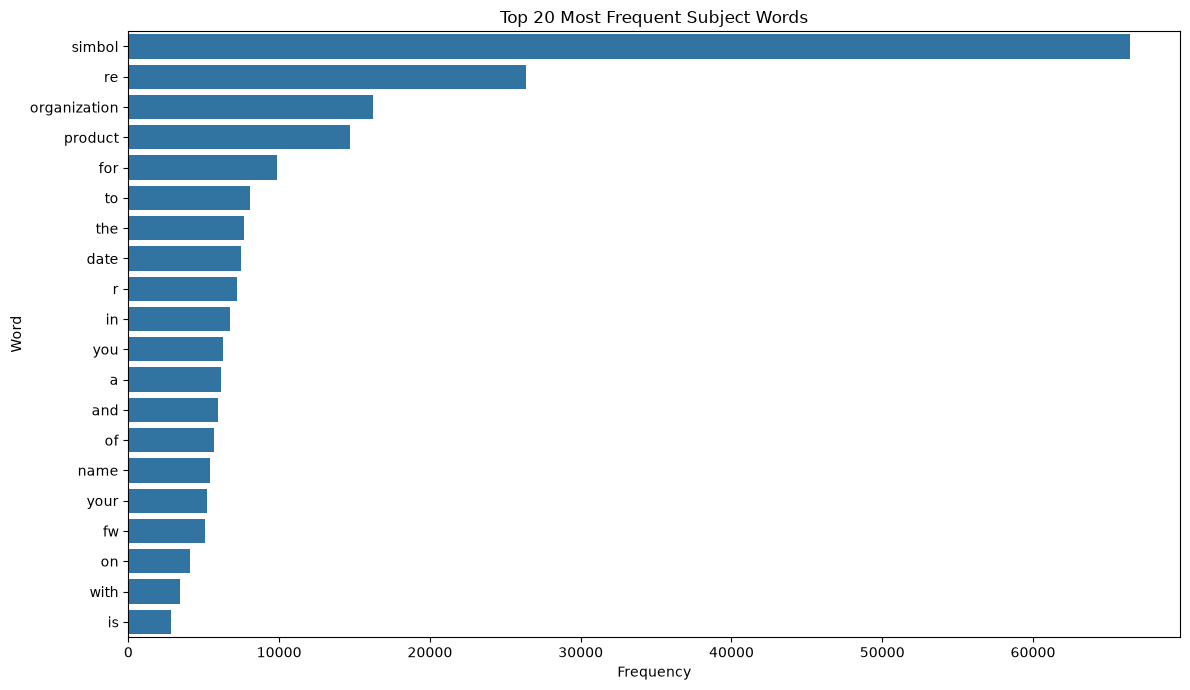

In [40]:
# Visualize the most frequent subject words
top_subject_words = subject_word_counts.most_common(20)

word_df = pd.DataFrame(
    top_subject_words,
    columns=["word", "frequency"]
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=word_df,
    x="frequency",
    y="word"
)

plt.title("Top 20 Most Frequent Subject Words")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.tight_layout()
plt.show()

In [41]:
#  Repeat the analysis for message bodies
body_tokens = []

for body in df["body"].dropna():
    body_tokens.extend(tokenize_text(body))

body_word_counts = Counter(body_tokens)

body_word_counts.most_common(20)

[('the', 736904),
 ('to', 501606),
 ('and', 372537),
 ('of', 322654),
 ('a', 311033),
 ('product', 297976),
 ('organization', 293803),
 ('name', 260594),
 ('you', 256324),
 ('i', 235102),
 ('in', 227201),
 ('is', 201393),
 ('for', 200744),
 ('this', 152090),
 ('that', 145276),
 ('on', 135776),
 ('your', 134880),
 ('it', 133619),
 ('with', 118971),
 ('be', 114967)]

In [42]:
# Compare vocabulary between Class 0 and Class 1
from collections import Counter

class_0_tokens = []
class_1_tokens = []

for text in df.loc[df["label"] == 0, "subject"].dropna():
    class_0_tokens.extend(tokenize_text(text))

for text in df.loc[df["label"] == 1, "subject"].dropna():
    class_1_tokens.extend(tokenize_text(text))

class_0_counts = Counter(class_0_tokens)
class_1_counts = Counter(class_1_tokens)

In [43]:
# Inspect the top 20 tokens for each class
print("Top 20 tokens in Class 0:")
print(class_0_counts.most_common(20))

print("\nTop 20 tokens in Class 1:")
print(class_1_counts.most_common(20))

Top 20 tokens in Class 0:
[('re', 22789), ('organization', 12419), ('product', 6964), ('r', 6904), ('date', 6657), ('for', 5280), ('in', 4816), ('fw', 4649), ('to', 3764), ('of', 3553), ('and', 3389), ('name', 3062), ('the', 2947), ('a', 2692), ('source', 2582), ('on', 2207), ('dmdx', 2065), ('hourahead', 1985), ('with', 1926), ('time', 1883)]

Top 20 tokens in Class 1:
[('simbol', 66364), ('product', 7719), ('you', 5683), ('the', 4700), ('your', 4667), ('for', 4588), ('to', 4272), ('organization', 3805), ('re', 3601), ('a', 3419), ('and', 2588), ('name', 2338), ('emoji', 2240), ('of', 2140), ('is', 1987), ('in', 1950), ('on', 1912), ('from', 1629), ('with', 1504), ('at', 1491)]


### Step 6: Class-Specific text analysis

In [44]:
simbol_mask = df["subject"].str.contains(
    r"<\|SIMBOL\|>",
    case=False,
    regex=True,
    na=False
)

print("Records containing SIMBOL:", simbol_mask.sum())

print("\nDistribution by label:")
print(
    df.loc[simbol_mask, "label"]
    .value_counts(dropna=False)
)

Records containing SIMBOL: 3438

Distribution by label:
label
1.0    3391
0.0      46
NaN       1
Name: count, dtype: int64


In [45]:
df.loc[
    simbol_mask,
    ["subject", "body", "source", "label"]
].head(10)

,subject,body,source,label
69,ÀÎÅÍ<|SIMBOL|>Ý Ä<|SIMBOL|><|SIMBOL|>å<|SIMBOL...,<|EMOJI|>FFFFB9<|EMOJI|>FFFFCF<|EMOJI|>FFFFC0<...,trec5,1.0
71,ÅëÇÕ<|SIMBOL|><|SIMBOL|><|SIMBOL|>ñ<|SIMBOL|><...,12-5<|EMOJI|>FFFFBD<|EMOJI|>FFFFB4<|EMOJI|>FFF...,trec5,1.0
72,(<|SIMBOL|>ì<|SIMBOL|>öÈ<|SIMBOL|><|SIMBOL|>ø<...,<|EMOJI|>FFFFBA<|EMOJI|>FFFFF1<|EMOJI|>FFFFC5<...,trec5,1.0
73,<|SIMBOL|>ù 1%<|SIMBOL|>ë <|SIMBOL|><|SIMBOL|>...,<|EMOJI|>FFFFB4<|EMOJI|>FFFFEB<|EMOJI|>FFFFC3<...,trec5,1.0
77,Á<|SIMBOL|>1<|SIMBOL|>ÝÀ<|SIMBOL|><|SIMBOL|>Ç ...,<|EMOJI|>FFFFA1<|EMOJI|>FFFFD8<|EMOJI|>FFFFC1<...,trec5,1.0
78,(<|SIMBOL|><|SIMBOL|><|SIMBOL|>í) <|SIMBOL|>óÂ...,b aojppvrasv oc\ngcduofeo a iv mego\nlzjgmimap...,trec5,1.0
79,<|SIMBOL|>á<|SIMBOL|>á<|SIMBOL|>á 100% <|SIMBO...,<|EMOJI|>FFFFC1<|EMOJI|>FFFFF7<|EMOJI|>FFFFC0<...,trec5,1.0
81,<|SIMBOL|><|SIMBOL|><|SIMBOL|>í) <|SIMBOL|>ÞÇÑ...,:: ?\n1 ::\nxwdhhlbn\nqzyhlawhieixcq i u dmfvc...,trec5,1.0
87,<|SIMBOL|>Â<|SIMBOL|>À<|SIMBOL|><|SIMBOL|>À<|S...,<|URL|>\nnyi rbrxwme\nmrtsc sp l\nxn ukoze\nno...,trec5,1.0
90,"ÇÁ<|SIMBOL|>ó<|SIMBOL|>Ù,<|SIMBOL|><|SIMBOL|>Â...",[ORGANIZATION]\nbbehgrpk\ntqigl\negjvw m rrcwb...,trec5,1.0


In [46]:
# Compare placeholder occurrence across classes
placeholder_analysis = (
    df.assign(contains_simbol=simbol_mask)
    .groupby("label")["contains_simbol"]
    .agg(["sum", "count", "mean"])
)

placeholder_analysis["percentage"] = (
    placeholder_analysis["mean"] * 100
)

placeholder_analysis

,sum,count,mean,percentage
label,,,,
0.0,46,60650,0.000758,0.075845
1.0,3391,48034,0.070596,7.059583


In [ ]:
# Improve the comparison: Normalize word frequencies
# Calculate normalized frequencies for each class

total_tokens_0 = sum(class_0_counts.values())
total_tokens_1 = sum(class_1_counts.values())

def normalized_frequency_comparison(
    counts_0,
    counts_1,
    total_0,
    total_1
):
    vocabulary = set(counts_0) | set(counts_1)

    comparison = pd.DataFrame({
        "word": list(vocabulary)
    })

    comparison["class_0_count"] = (
        comparison["word"]
        .map(counts_0)
        .fillna(0)
        .astype(int)
    )

    comparison["class_1_count"] = (
        comparison["word"]
        .map(counts_1)
        .fillna(0)
        .astype(int)
    )

    comparison["class_0_per_1000_tokens"] = (
        comparison["class_0_count"] / total_0 * 1000
    )

    comparison["class_1_per_1000_tokens"] = (
        comparison["class_1_count"] / total_1 * 1000
    )

    comparison["frequency_difference"] = (
        comparison["class_1_per_1000_tokens"]
        - comparison["class_0_per_1000_tokens"]
    )

    return comparison.sort_values(
        "frequency_difference",
        ascending=False
    )

In [48]:
word_comparison = normalized_frequency_comparison(
    class_0_counts,
    class_1_counts,
    total_tokens_0,
    total_tokens_1
)

word_comparison.head(20)

,word,class_0_count,class_1_count,class_0_per_1000_tokens,class_1_per_1000_tokens,frequency_difference
19903,simbol,52,66364,0.170933,208.130265,207.959331
9842,you,615,5683,2.021617,17.822981,15.801364
2334,your,571,4667,1.876981,14.636609,12.759629
2543,emoji,1,2240,0.003287,7.025071,7.021784
10836,the,2947,4700,9.687323,14.740104,5.052780
6860,we,128,1450,0.420759,4.547479,4.126720
21010,it,290,1457,0.953283,4.569432,3.616150
1395,price,92,1216,0.302421,3.813610,3.511189
13555,our,78,1156,0.256400,3.625438,3.369038
23227,is,871,1987,2.863135,6.231614,3.368479


In [49]:
# Count placeholder occurrences in subjects and bodies
placeholders = [
    "SIMBOL",
    "EMOJI",
    "URL",
    "ORGANIZATION",
    "PRODUCT",
    "NAME"
]

for placeholder in placeholders:
    pattern = rf"<\|{placeholder}\|>"

    subject_count = df["subject"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False
    ).sum()

    body_count = df["body"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False
    ).sum()

    print(f"\nPlaceholder: {placeholder}")
    print(f"Subject records: {subject_count}")
    print(f"Body records: {body_count}")


Placeholder: SIMBOL
Subject records: 3438
Body records: 0

Placeholder: EMOJI
Subject records: 684
Body records: 4498

Placeholder: URL
Subject records: 351
Body records: 27224

Placeholder: ORGANIZATION
Subject records: 0
Body records: 0

Placeholder: PRODUCT
Subject records: 0
Body records: 0

Placeholder: NAME
Subject records: 0
Body records: 0


In [50]:
# Compare placeholder occurrences across classes
for placeholder in placeholders:
    pattern = rf"<\|{placeholder}\|>"

    subject_mask = df["subject"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False
    )

    body_mask = df["body"].str.contains(
        pattern,
        case=False,
        regex=True,
        na=False
    )

    print(f"\n{'=' * 45}")
    print(f"Placeholder: {placeholder}")
    print(f"{'=' * 45}")

    for col_name, mask in [
        ("Subject", subject_mask),
        ("Body", body_mask)
    ]:
        rates = (
            df.assign(contains_placeholder=mask)
            .groupby("label")["contains_placeholder"]
            .agg(["sum", "mean"])
        )

        rates["percentage"] = rates["mean"] * 100

        print(f"\n{col_name}:")
        print(rates[["sum", "percentage"]])


Placeholder: SIMBOL

Subject:
        sum  percentage
label                  
0.0      46    0.075845
1.0    3391    7.059583

Body:
       sum  percentage
label                 
0.0      0         0.0
1.0      0         0.0

Placeholder: EMOJI

Subject:
       sum  percentage
label                 
0.0      1    0.001649
1.0    683    1.421909

Body:
        sum  percentage
label                  
0.0     604    0.995878
1.0    3893    8.104676

Placeholder: URL

Subject:
       sum  percentage
label                 
0.0    319    0.525969
1.0     32    0.066619

Body:
         sum  percentage
label                   
0.0    11721   19.325639
1.0    15503   32.275055

Placeholder: ORGANIZATION

Subject:
       sum  percentage
label                 
0.0      0         0.0
1.0      0         0.0

Body:
       sum  percentage
label                 
0.0      0         0.0
1.0      0         0.0

Placeholder: PRODUCT

Subject:
       sum  percentage
label                 
0.0      0      